# Week 2 - Feature Engineering Report
**Iran the Numbers** | Iranian Churn | Can engineered usage features compensate for missing warning flags?

Primary metric: average precision (AP), 5-fold StratifiedKFold on the training split.
Every step is compared with the baseline; all numbers are collected in the results log (section 10).

## 0. Setup

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from ucimlrepo import fetch_ucirepo

from sklearn import set_config
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, FunctionTransformer
from sklearn.feature_selection import RFECV, SelectFromModel
from sklearn.linear_model import LogisticRegression

set_config(transform_output="pandas")

RANDOM_STATE = 42
UCI_DATASET_ID = 563
TARGET = "churn"

## 1. Load data

Loaded from the UCI repository via `ucimlrepo`. Raw column names contain double spaces have been normalised to snake_case.

In [2]:
iranian_churn = fetch_ucirepo(id=UCI_DATASET_ID)
df = iranian_churn.data.original

# Названия вида 'Call  Failure' (двойной пробел) стало просто 'call_failure'
df.columns = df.columns.str.strip().str.lower().str.replace(r"\s+", "_", regex=True)
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 3150 entries, 0 to 3149
Data columns (total 14 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   call_failure             3150 non-null   int64  
 1   complains                3150 non-null   int64  
 2   subscription_length      3150 non-null   int64  
 3   charge_amount            3150 non-null   int64  
 4   seconds_of_use           3150 non-null   int64  
 5   frequency_of_use         3150 non-null   int64  
 6   frequency_of_sms         3150 non-null   int64  
 7   distinct_called_numbers  3150 non-null   int64  
 8   age_group                3150 non-null   int64  
 9   tariff_plan              3150 non-null   int64  
 10  status                   3150 non-null   int64  
 11  age                      3150 non-null   int64  
 12  customer_value           3150 non-null   float64
 13  churn                    3150 non-null   int64  
dtypes: float64(1), int64(13)
memory usa

In [3]:
# Баланс классов доля ушедших (1) и оставшихся (0)
df[TARGET].value_counts(normalize=True)

churn
0    0.842857
1    0.157143
Name: proportion, dtype: float64

### 1.1 Feature summary table

| Original feature | Decision (keep / transform / encode / remove) | Justification |
|---|---|---|
| `call_failure` | transform into `failure_rate` (+ log1p for LR) | Raw count alone is uninformative (r = 0.003 with churn; churn rate flat at 14-17% across quartiles); failures only matter relative to how much the customer calls. |
| `complains` | keep in set A, **remove** in B/C (by design) | Near-label flag: 82.6% churn when 1 vs 9.8% when 0. Recorded only after dissatisfaction is explicit, so the RQ tests the model without it. Already 0/1, so no encoding. |
| `subscription_length` | keep as-is | The only left-skewed feature (skew -1.25), so log1p doesn't apply. Relation to churn is non-monotonic (12%, 21%, 17%, 11% by quartile), which trees capture and LR can't. |
| `charge_amount` | keep as ordinal (0-10), no one-hot | Monotonic link to churn (23.7% churn at 0, 0% at 5 and above), which an integer code preserves. Levels 5-10 have only 7-30 customers each, so one-hot would create sparse columns. |
| `seconds_of_use` | transform (log1p), then **removed by L1** (section 9) | r = 0.945 with `frequency_of_use`; dropping it alone changes AP within noise (from 0.754 to 0.750); L1 removes it once `avg_call_duration` carries its information. |
| `frequency_of_use` | transform: log1p + denominator of all three ratios | Main measure of activity (r = -0.30 with churn, the strongest behavioural signal). The pair with `seconds_of_use` is resolved by CV, and the ratio keeps the information from both. |
| `frequency_of_sms` | transform: log1p + `sms_share` | skew 1.97, 18% zeros. Kept over `customer_value` (r = 0.923): directly interpretable, same AP. |
| `distinct_called_numbers` | transform (log1p), then **removed by L1** (section 9) | skew 1.04; r = 0.73 with `frequency_of_use` - below 0.90, but L1 finds it redundant with activity counts. |
| `age_group` | keep (ordinal 1-5) | Exact 1:1 mapping to `age` (each group has a single age: 15/25/30/45/55), so only one of the two is needed. Near-zero link to churn (r = -0.006). |
| `tariff_plan` | keep (binary) | 92% of customers are on plan 1, so check in the variance analysis, but don't remove: churn is 2.6% on plan 2 vs 16.8% on plan 1. |
| `status` | keep in set A, **remove** in B/C (by design) | Inactive customers churn at 47.5% vs 5.6%. Inactivity is a late symptom of leaving rather than an early signal, so it is excluded together with `complains`. |
| `age` | **remove** | Same information as `age_group` (r = 0.961, 1:1 mapping); dropping it keeps AP at 0.754. |
| `customer_value` | **remove** | Opaque operator score, r = 0.923 with `frequency_of_sms`; dropping it keeps AP at 0.754, and the interpretable SMS count stays. |

## 2. Duplicate handling

In [4]:
# Полностью одинаковые строки убираем ДО split, иначе одна и та же строка попадёт и в train, и в test
print("Duplicates:", df.duplicated().sum())
df_with_dups = df.copy()  # копия с дубликатами для проверки чувствительности в section 4
df = df.drop_duplicates().reset_index(drop=True)
print("Rows left:", len(df))

Duplicates: 300
Rows left: 2850


300 of 3150 rows (9.5%) are exact duplicates have been dropped before the split so identical rows can't land in both train and test.
2850 rows remain, class balance barely changes (from 15.7% to 15.6% churn).

## 3. Train/test split

In [5]:
X = df.drop(columns=TARGET)
y = df[TARGET]

# stratify=y сохраняет долю churn (~16%) одинаковой в train и test
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=RANDOM_STATE
)
X_train.shape, X_test.shape

((2280, 13), (570, 13))

Stratified 80/20. `X_test` is not used for any metric, only the final Pipeline cell applies it as a shape check.

## 4. Baseline

Every step below builds its pipeline explicitly and is scored the same way: 5-fold CV on the training set, metric AP.
Each result is appended to `results` (shown in section 10).

In [6]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

# Сюда записываем результат каждого шага: (шаг, число признаков, AP mean, AP std)
results = []

# Baseline: все 13 исходных признаков, масштабирование + логистическая регрессия
baseline = Pipeline([
    ("scale", StandardScaler()),
    ("model", LogisticRegression(max_iter=1000)),
])

scores = cross_val_score(baseline, X_train, y_train, scoring="average_precision", cv=cv)
results.append(("baseline", 13, scores.mean(), scores.std()))
print(f"Baseline AP: {scores.mean():.3f} +/- {scores.std():.3f}")

Baseline AP: 0.754 +/- 0.021


Baseline: Logistic Regression on all 13 original features. StandardScaler is part of the baseline without it LR's regularisation treats features on different scales (0-17090 vs 0-1) unequally.

### 4.1 Duplicate sensitivity check (from the proposal)

In [7]:
from sklearn.model_selection import StratifiedGroupKFold

# Проверка из proposal: что будет с оценкой, если дубликаты НЕ удалять.
# Берём строки с дубликатами, но только те, что совпадают со строками train (test не трогаем)
train_rows = pd.concat([X_train, y_train], axis=1)
dups = df_with_dups.merge(train_rows, how="inner")
X_dups = dups.drop(columns=TARGET)
y_dups = dups[TARGET]
print("Train rows with duplicates:", len(dups))

# Grouped CV: одинаковые строки получают один номер группы, поэтому все копии попадают в один фолд
groups = dups.groupby(list(dups.columns)).ngroup()
grouped_cv = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
grouped = cross_val_score(baseline, X_dups, y_dups, groups=groups, scoring="average_precision", cv=grouped_cv)
print(f"With duplicates, grouped CV: {grouped.mean():.3f} +/- {grouped.std():.3f}")

# Обычный CV: копии одной строки могут попасть и в обучение, и в проверку
plain = cross_val_score(baseline, X_dups, y_dups, scoring="average_precision", cv=cv)
print(f"With duplicates, plain CV:   {plain.mean():.3f} +/- {plain.std():.3f}")

Train rows with duplicates: 2532
With duplicates, grouped CV: 0.753 +/- 0.064
With duplicates, plain CV:   0.755 +/- 0.036


**Duplicate sensitivity:** keeping the duplicates does not change the score: 0.753 with grouped CV (copies of a row stay in one fold) and 0.755 with plain CV, vs 0.754 on deduplicated data all within noise (std 0.02-0.06). There is no sign that the duplicates inflate the score here. Removing them before the split stays the default: it is the safe choice and costs nothing.

## 5. Variance analysis

In [8]:
# Доля самого частого значения: если близка к 1, признак почти константа
top_share = X_train.apply(lambda c: c.value_counts(normalize=True).iloc[0]).sort_values(ascending=False)
top_share.round(3).to_frame("most frequent val ue share").head()

,most frequent val ue share
tariff_plan,0.922
complains,0.920
status,0.761
charge_amount,0.556
age_group,0.445


In [9]:
# Для двух самых "константных" признаков смотрим, отличается ли churn между значениями
for col in ["complains", "tariff_plan"]:
    print(y_train.groupby(X_train[col]).mean().round(3).to_dict())

{0: 0.1, 1: 0.813}
{1: 0.168, 2: 0.022}


**Evaluation:** no feature is constant. The lowest-variance ones, `complains` and `tariff_plan` (~92% one value),
have very different churn rates between their values (81% vs 10%; 2% vs 17%), so removing them would lose signal. **Nothing removed, AP unchanged** (same as baseline).

## 6. Correlation analysis (|r| > 0.90)

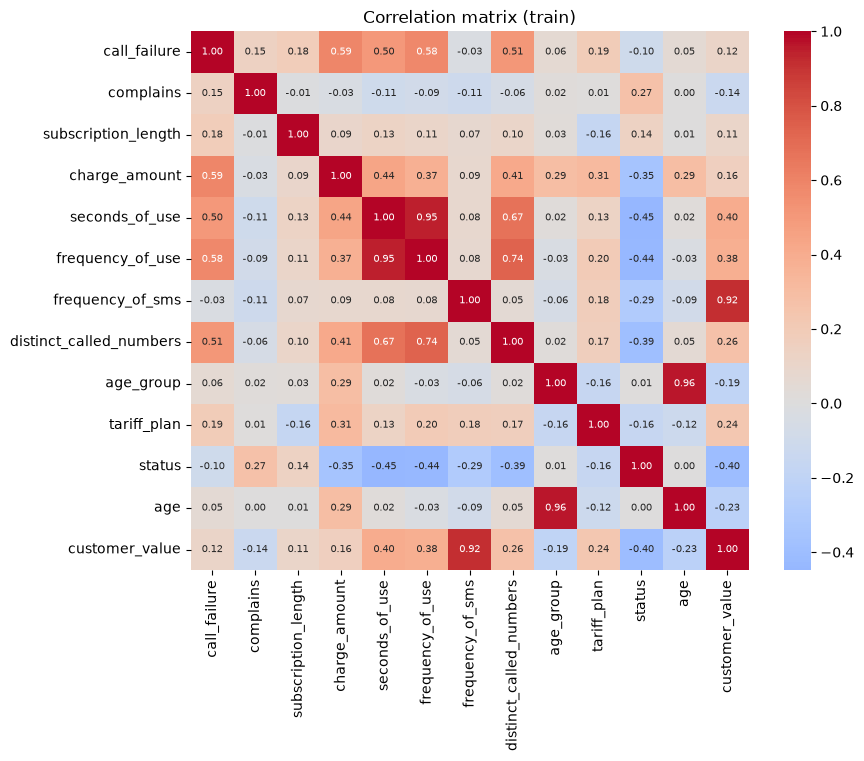

seconds_of_use    frequency_of_use    0.946
frequency_of_sms  customer_value      0.921
age_group         age                 0.962
dtype: float64

In [10]:
corr = X_train.corr()
plt.figure(figsize=(9, 7))
sns.heatmap(corr, cmap="coolwarm", center=0, annot=True, fmt=".2f", annot_kws={"size": 7})
plt.title("Correlation matrix (train)")
plt.show()

# Пары с |r| > 0.90
pairs = corr.abs().where(np.triu(np.ones(corr.shape, dtype=bool), k=1)).stack()
pairs[pairs > 0.9].round(3)

In [11]:
# Для каждой пары пробуем удалить один из признаков и сравниваем AP с baseline (0.754)
for col in ["age", "seconds_of_use", "frequency_of_use", "customer_value", "frequency_of_sms"]:
    scores = cross_val_score(baseline, X_train.drop(columns=[col]), y_train,
                             scoring="average_precision", cv=cv)
    results.append((f"drop {col}", 12, scores.mean(), scores.std()))
    print(f"drop {col:<18} AP: {scores.mean():.3f} +/- {scores.std():.3f}")

drop age                AP: 0.754 +/- 0.020
drop seconds_of_use     AP: 0.750 +/- 0.020
drop frequency_of_use   AP: 0.730 +/- 0.029
drop customer_value     AP: 0.754 +/- 0.020
drop frequency_of_sms   AP: 0.755 +/- 0.018


**Evaluation:** three pairs above 0.90. CV std is ~0.02, so differences smaller than that are treated as noise.
- `age` / `age_group` (0.96): identical information (1:1 mapping), so drop `age`; AP stays at 0.754.
- `frequency_of_sms` / `customer_value` (0.92): dropping either leaves AP unchanged (0.754 / 0.755), so drop `customer_value`, an opaque operator score; `frequency_of_sms` is directly interpretable.
- `seconds_of_use` / `frequency_of_use` (0.95): dropping `frequency_of_use` costs about one std (from 0.754 to 0.730), so keep it. Dropping `seconds_of_use` is within noise (0.750) - keep it for now and leave the call to feature selection (section 9).

In [12]:
# Итог раздела 6: удаляем age и customer_value.
# Все следующие эксперименты работают с этим набором из 11 признаков
X_train_clean = X_train.drop(columns=["age", "customer_value"])
X_train_clean.shape

(2280, 11)

## 7. Engineered features

- `avg_call_duration = seconds_of_use / (frequency_of_use + 1)` - long vs short calls, independent of activity level
- `sms_share = frequency_of_sms / (frequency_of_sms + frequency_of_use + 1)` - how the customer communicates
- `failure_rate = call_failure / (frequency_of_use + 1)` - raw failures are uninformative (r ~0 with churn); failures per call are not

Implemented as a FunctionTransformer, so it lives inside the Pipeline.

In [13]:
def add_ratios(X):
    # Три новых признака; +1 в знаменателе, чтобы не делить на 0
    X = X.copy()
    X["avg_call_duration"] = X["seconds_of_use"] / (X["frequency_of_use"] + 1)
    X["sms_share"] = X["frequency_of_sms"] / (X["frequency_of_sms"] + X["frequency_of_use"] + 1)
    X["failure_rate"] = X["call_failure"] / (X["frequency_of_use"] + 1)
    return X


pipe_ratios = Pipeline([
    ("ratios", FunctionTransformer(add_ratios)),
    ("scale", StandardScaler()),
    ("model", LogisticRegression(max_iter=1000)),
])

scores = cross_val_score(pipe_ratios, X_train_clean, y_train, scoring="average_precision", cv=cv)
results.append(("+ 3 ratios", 14, scores.mean(), scores.std()))
print(f"+ 3 ratios AP: {scores.mean():.3f} +/- {scores.std():.3f}")

+ 3 ratios AP: 0.753 +/- 0.019


**Evaluation:** AP from 0.754 to 0.753 - **no measurable effect** for Logistic Regression. The ratios are kept because they are the features the research question tests (set C in Week 3), and their effect on tree models is still to be measured there.

## 8. log1p on skewed counts

In [14]:
# Скошенность (skew > 1 длинный правый хвост).
# log1p применяем к счётным признакам; complains, tariff_plan и status - это 0/1, их не трогаем
X_train_clean.skew().round(2).sort_values(ascending=False)

tariff_plan                3.15
complains                  3.10
charge_amount              2.55
frequency_of_sms           1.98
seconds_of_use             1.30
status                     1.22
frequency_of_use           1.14
call_failure               1.11
distinct_called_numbers    1.04
age_group                  0.47
subscription_length       -1.28
dtype: float64

In [15]:
def log_counts(X):
    # log1p(x) = log(1 + x): сжимает длинный хвост, а +1 нужен, потому что log(0) не определён
    X = X.copy()
    for col in ["call_failure", "seconds_of_use", "frequency_of_use",
                "frequency_of_sms", "distinct_called_numbers", "charge_amount"]:
        X[col] = np.log1p(X[col])
    return X


pipe_log = Pipeline([
    ("ratios", FunctionTransformer(add_ratios)),  # сначала ratio из исходных значений
    ("log", FunctionTransformer(log_counts)),     # потом log1p исходных счётчиков
    ("scale", StandardScaler()),
    ("model", LogisticRegression(max_iter=1000)),
])

scores = cross_val_score(pipe_log, X_train_clean, y_train, scoring="average_precision", cv=cv)
results.append(("+ ratios + log1p", 14, scores.mean(), scores.std()))
print(f"+ ratios + log1p AP: {scores.mean():.3f} +/- {scores.std():.3f}")

+ ratios + log1p AP: 0.762 +/- 0.022


**Evaluation:** AP from 0.753 to 0.762  a **small gain within CV noise** (+0.009 vs std ~0.02). log1p is kept because it is cheap and consistent with the data: the counts have skew 1.0-2.6, and compressing the tails stops a few heavy users from dominating the linear weights. It is not evidence of a real improvement on its own.

**Encoding:** all features are already numeric binary (`complains`, `tariff_plan`, `status`) and ordinal
(`age_group` 1-5, `charge_amount` 0-10), so no encoder is needed; one-hot would only add sparse columns.
ColumnTransformer is still used in the final Pipeline, to drop the two columns removed in section 6.

**Scaling:** StandardScaler for Logistic Regression (scale-sensitive regularisation). Tree models in Week 3 won't need it.

## 9. Feature selection

In [16]:
# Метод 1: RFECV убирает признаки по одному, пока AP на CV не начнёт падать
pipe_rfecv = Pipeline([
    ("ratios", FunctionTransformer(add_ratios)),
    ("log", FunctionTransformer(log_counts)),
    ("scale", StandardScaler()),
    ("select", RFECV(LogisticRegression(max_iter=1000), cv=cv, scoring="average_precision")),
    ("model", LogisticRegression(max_iter=1000)),
])

scores_rfecv = cross_val_score(pipe_rfecv, X_train_clean, y_train, scoring="average_precision", cv=cv)

# Обучаем на всём train, чтобы посмотреть, какие признаки остались
pipe_rfecv.fit(X_train_clean, y_train)
selected_rfecv = list(pipe_rfecv.named_steps["select"].get_feature_names_out())

results.append(("+ RFECV", len(selected_rfecv), scores_rfecv.mean(), scores_rfecv.std()))
print(f"RFECV AP: {scores_rfecv.mean():.3f} +/- {scores_rfecv.std():.3f}, features: {len(selected_rfecv)}")

RFECV AP: 0.761 +/- 0.024, features: 13


In [17]:
# Метод 2: L1-регуляризация - зануляет веса бесполезных признаков, остаются признаки с ненулевым весом
pipe_l1 = Pipeline([
    ("ratios", FunctionTransformer(add_ratios)),
    ("log", FunctionTransformer(log_counts)),
    ("scale", StandardScaler()),
    ("select", SelectFromModel(LogisticRegression(l1_ratio=1, solver="liblinear", C=0.1))),
    ("model", LogisticRegression(max_iter=1000)),
])

scores_l1 = cross_val_score(pipe_l1, X_train_clean, y_train, scoring="average_precision", cv=cv)

pipe_l1.fit(X_train_clean, y_train)
selected_l1 = list(pipe_l1.named_steps["select"].get_feature_names_out())

results.append(("+ L1 LR", len(selected_l1), scores_l1.mean(), scores_l1.std()))
print(f"L1 AP: {scores_l1.mean():.3f} +/- {scores_l1.std():.3f}, features: {len(selected_l1)}")

L1 AP: 0.760 +/- 0.024, features: 12


In [18]:
# Сравнение двух методов: что выбрали, что удалили, какой AP
all_features = list(X_train_clean.columns) + ["avg_call_duration", "sms_share", "failure_rate"]

comparison = pd.DataFrame({
    "method": ["RFECV", "L1 LR"],
    "n features": [len(selected_rfecv), len(selected_l1)],
    "AP mean": [round(scores_rfecv.mean(), 3), round(scores_l1.mean(), 3)],
    "AP std": [round(scores_rfecv.std(), 3), round(scores_l1.std(), 3)],
    "selected": [selected_rfecv, selected_l1],
    "removed": [[f for f in all_features if f not in selected_rfecv],
                [f for f in all_features if f not in selected_l1]],
})

# Полные списки признаков в ячейках таблицы
with pd.option_context("display.max_colwidth", None):
    display(comparison)

,method,n features,AP mean,AP std,selected,removed
0,RFECV,13,0.761,0.024,"[call_failure, complains, subscription_length, charge_amount, seconds_of_use, frequency_of_use, frequency_of_sms, distinct_called_numbers, age_group, tariff_plan, status, avg_call_duration, failure_rate]",[sms_share]
1,L1 LR,12,0.760,0.024,"[call_failure, complains, subscription_length, charge_amount, frequency_of_use, frequency_of_sms, age_group, tariff_plan, status, avg_call_duration, sms_share, failure_rate]","[seconds_of_use, distinct_called_numbers]"


**Decision:** both methods match the full set (0.762): RFECV 0.761 with 13 features, L1 0.760 with 12. The differences are well within CV noise, so we pick **L1 (12 features)** the simpler model at the same score. It removes `seconds_of_use` (its information is in `avg_call_duration`) and `distinct_called_numbers` (r = 0.73 with `frequency_of_use`). The two methods disagree on what is redundant (RFECV drops only `sms_share`), which is another sign that these features carry overlapping information.

## 10. Results log & dimensionality reduction

In [19]:
pd.DataFrame(results, columns=["step", "n features", "AP mean", "AP std"]).round(3)

,step,n features,AP mean,AP std
0,baseline,13,0.754,0.021
1,drop age,12,0.754,0.020
2,drop seconds_of_use,12,0.750,0.020
3,drop frequency_of_use,12,0.730,0.029
4,drop customer_value,12,0.754,0.020
5,drop frequency_of_sms,12,0.755,0.018
6,+ 3 ratios,14,0.753,0.019
7,+ ratios + log1p,14,0.762,0.022
8,+ RFECV,13,0.761,0.024
9,+ L1 LR,12,0.760,0.024


**Dimensionality reduction: N/A.** After selection the model sees <= 20 features (12), so PCA is not required by the guide
and would also make the features uninterpretable for the app's explanations.

**Final feature set:** 12 features - `call_failure`, `complains`, `subscription_length`, `charge_amount`, `frequency_of_use`, `frequency_of_sms`, `age_group`, `tariff_plan`, `status`, `avg_call_duration`, `sms_share`, `failure_rate`. Original dataset: 13 predictors.

## 11. Final Pipeline

Single self-contained object: drop columns (ColumnTransformer), ratios, log1p, imputer, scaler, L1 feature selector, placeholder LR, in this order. Input is the raw 13-feature `X_train`.

In [20]:
# Финальный pipeline: все решения выше в одном объекте.
# На вход подаются исходные 13 признаков, удаление колонок тоже происходит внутри
final_pipeline = Pipeline([
    ("drop", ColumnTransformer([("drop", "drop", ["age", "customer_value"])],    # section 6
                               remainder="passthrough", verbose_feature_names_out=False)),
    ("ratios", FunctionTransformer(add_ratios)),                                  # section 7
    ("log", FunctionTransformer(log_counts)),                                     # section 8
    ("impute", SimpleImputer(strategy="median")),  # в train пропусков нет, страховка для новых данных (CSV в приложении)
    ("scale", StandardScaler()),
    ("select", SelectFromModel(LogisticRegression(l1_ratio=1, solver="liblinear", C=0.1))),  # section 9, L1
    ("model", LogisticRegression(max_iter=1000)),
])

final_pipeline.fit(X_train, y_train)

# Проверка: pipeline применяется к train и test, число признаков на выходе совпадает
print("X_train after preprocessing:", final_pipeline[:-1].transform(X_train).shape)
print("X_test  after preprocessing:", final_pipeline[:-1].transform(X_test).shape)
print("Predictions on X_test:", final_pipeline.predict(X_test).shape)
final_pipeline

X_train after preprocessing: (2280, 12)
X_test  after preprocessing: (570, 12)
Predictions on X_test: (570,)


,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('drop', ...), ('ratios', ...), ...]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](2,)","[0,1]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](13,)","['call_failure','complains','subscription_length',...,'status','age', 'customer_value']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,13
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('drop', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all